# Good Book For Deep Learning Engineers:
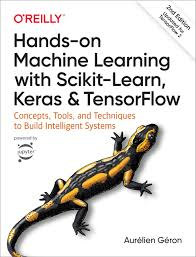

# Tutorial on PCA

## Import necessary packages

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import pandas as pd

## A simple example

Shape of X =  (200, 2)


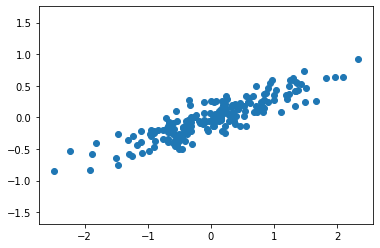

In [ ]:
# Use a specific random number
rng = np.random.RandomState(1)

# Create a 2D array of random numbers using uniform distribution and normal distribution
X = np.dot(rng.rand(2, 2), rng.randn(2, 200)).T

print("Shape of X = ", X.shape)

# Scatter plot the points
plt.scatter(X[:, 0], X[:, 1])
plt.axis('equal');

By eye, it is clear that there is a nearly linear relationship between the x and y variables. In principal component analysis, this relationship is quantified by finding a list of the *principal axes* in the data, and using those axes to describe the dataset.
Using Scikit-Learn's ``PCA`` estimator, we can compute this as follows:

In [ ]:
from sklearn.decomposition import PCA

# Define an object of PCA class with 2 components
pca = PCA(n_components=2)

# Fit the PCA object on the data
pca.fit(X)

PCA(n_components=2)

The fit learns some quantities from the data, most importantly the "components" and "explained variance":

In [ ]:
print(pca.components_)

[[-0.94446029 -0.32862557]
 [-0.32862557  0.94446029]]


In [ ]:
print(pca.explained_variance_)

[0.7625315 0.0184779]


To see what these numbers mean, let's visualize them as vectors over the input data, using the "components" to define the direction of the vector, and the "explained variance" to define the squared-length of the vector:

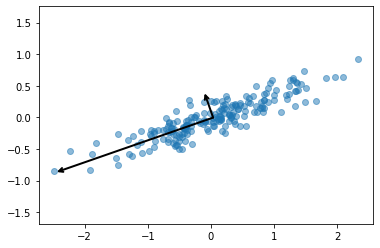

In [ ]:
def draw_vector(v0, v1, ax=None):
    ax = ax or plt.gca()

    arrowprops = dict(arrowstyle='->',
                      linewidth=2,
                      shrinkA=0,
                      shrinkB=0,
                      color='black')

    # Draw an arrow pointing from v0 to v1
    ax.annotate('', v1, v0, arrowprops=arrowprops)

# Plot data
plt.scatter(X[:, 0], X[:, 1], alpha=0.5)

# Iterate over the PCA components
for length, vector in zip(pca.explained_variance_, pca.components_):

    # Get the direction and magnitude of the vector
    v = vector * 3 * np.sqrt(length)

    # Draw the vector with mean as origin
    draw_vector(pca.mean_, pca.mean_ + v)

plt.axis('equal');

## PCA for visualization: Hand-written digits

In [ ]:
from sklearn.datasets import load_digits
digits = load_digits()

# Print shape of the dataset
digits.data.shape

(1797, 64)

In [ ]:
# Classes in the dataset
np.unique(digits.target)

array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])

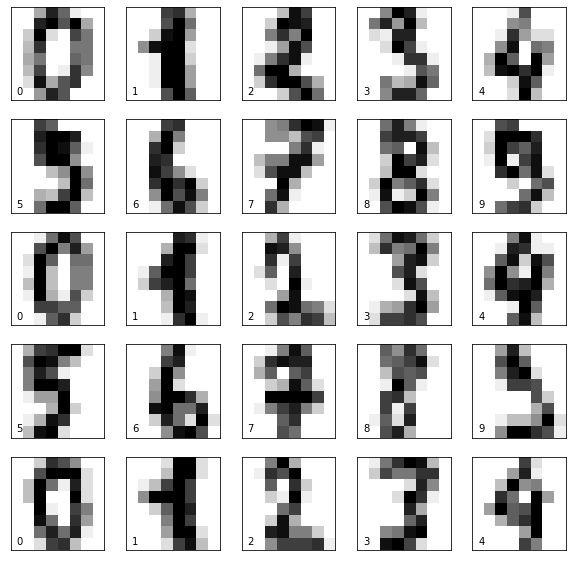

In [ ]:
# Plot samples from the dataset
fig = plt.figure(figsize=(10, 10))

for i in range(25):
    ax = fig.add_subplot(5, 5, i + 1, xticks=[], yticks=[])
    ax.imshow(digits.images[i], cmap=plt.cm.binary)
    # label the image with the target value
    ax.text(0, 7, str(digits.target[i]))

In [ ]:
# Normalize the input
standard_scaler = StandardScaler()

data = standard_scaler.fit_transform(digits.data)

In [ ]:
# Project from 64 to 2 dimensions
pca = PCA(2)

# Fit and transform the dataset
projected = pca.fit_transform(data)
print(data.shape)
print(projected.shape)

(1797, 64)
(1797, 2)


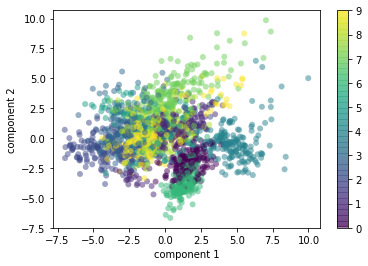

In [ ]:
# Plot the components and color code by class
plt.scatter(projected[:, 0], projected[:, 1],
            c=digits.target, edgecolor='none', alpha=0.5,
           )
plt.xlabel('component 1')
plt.ylabel('component 2')
plt.colorbar();

# Our Implementation of PCA

In [ ]:
def PCA_own(data, n_components=None):
    # Since PCA is unsupervised, we only input the data

    # if n_components is None, return all the components of PCA
    if n_components == None:
        n_components = data.shape[1]

    # Compute covariance matrix of the data
    covmat = np.cov(data.T)
    eig_vals, eig_vecs = np.linalg.eig(covmat)

    # Index of sorted eigvalues in descending order
    sort_idx = np.argsort(eig_vals)[::-1]

    # Sort eigenvalues and eigenvectors in descending order
    eig_vals, eig_vecs = eig_vals[sort_idx], eig_vecs.T[sort_idx]

    # Matrix multiply data with eigenvectors to project them to new space
    projected = data @ eig_vecs[:n_components].T

    return projected, eig_vecs[:n_components]

In [ ]:
# Calculate the projections and eigenvectors of PCA
projected2, projected2_eig_vecs = PCA_own(np.array(data), n_components=2)

print("Shape of projected data = ", projected2.shape)
print("Shape of eigen vectors = ", projected2_eig_vecs.shape)

Shape of projected data =  (1797, 2)
Shape of eigen vectors =  (2, 64)


### Let's compare our method with sklearn

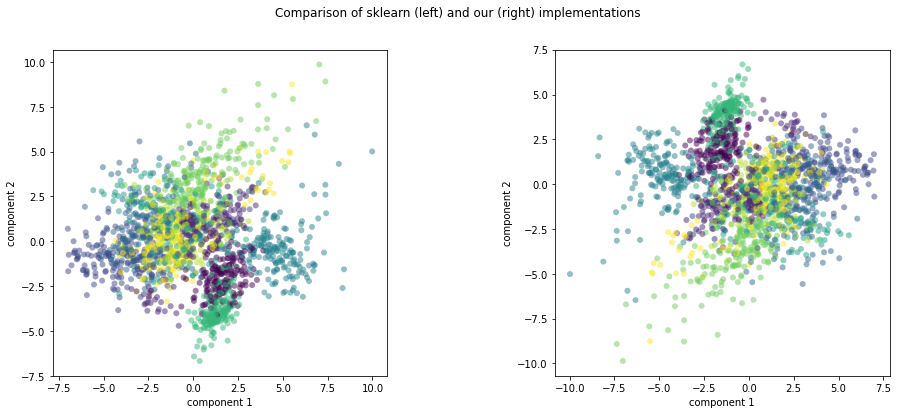

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2,figsize=(15,6))

fig.subplots_adjust(wspace=.5)
fig.suptitle('Comparison of sklearn (left) and our (right) implementations')

# Plot the sklearn implementation
ax1.scatter(projected[:, 0], projected[:, 1],
            c=digits.target, edgecolor='none', alpha=0.5)
ax1.set(xlabel='component 1', ylabel='component 2')

# Plot our implementation
ax2.scatter(projected2[:, 0], projected2[:, 1],
            c=digits.target, edgecolor='none', alpha=0.5)
ax2.set(xlabel='component 1', ylabel='component 2');

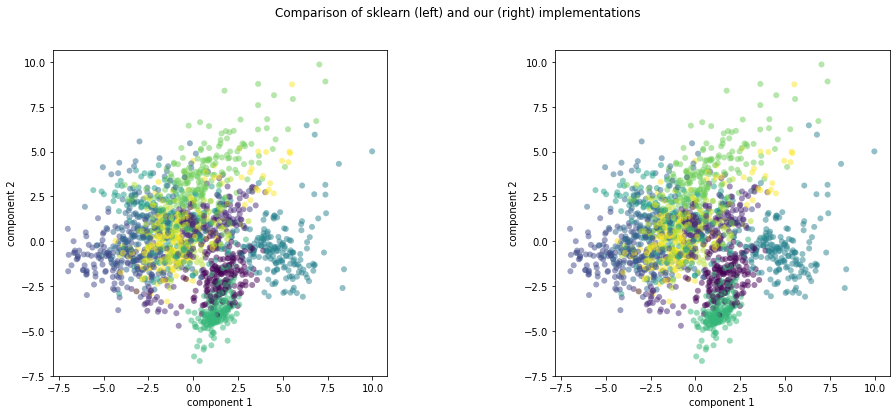

In [ ]:
# Flip the axes
fig, (ax1, ax2) = plt.subplots(1, 2,figsize=(15,6))

fig.subplots_adjust(wspace=.5)
fig.suptitle('Comparison of sklearn (left) and our (right) implementations')

# Plot the sklearn implementation
ax1.scatter(projected[:, 0], projected[:, 1],
            c=digits.target, edgecolor='none', alpha=0.5)
ax1.set(xlabel='component 1', ylabel='component 2')

# Plot our implementation
ax2.scatter(-projected2[:, 0], -projected2[:, 1],
            c=digits.target, edgecolor='none', alpha=0.5)
ax2.set(xlabel='component 1', ylabel='component 2');

### Choosing the number of components
A vital part of using PCA in practice is the ability to estimate how many components are needed to describe the data. This can be determined by looking at the cumulative explained variance ratio as a function of the number of components:

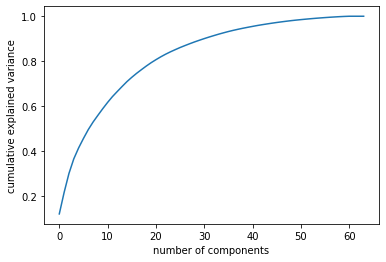

In [ ]:
pca = PCA().fit(data)

# Plot cumulative sum of the explained variance ratio.
plt.plot(np.cumsum(pca.explained_variance_ratio_))
plt.xlabel('number of components')
plt.ylabel('cumulative explained variance');

This curve quantifies how much of the total, 64-dimensional variance is contained within the first  N  components. For example, we see that with the digits the first 10 components contain approximately 75% of the variance, while you need around 40 components to describe close to 100% of the variance.

Here we see that our two-dimensional projection loses a lot of information (as measured by the explained variance) and that we'd need about 20 components to retain 90% of the variance. Looking at this plot for a high-dimensional dataset can help you understand the level of redundancy present in multiple observations.

# Try it yourself!



Use the first two components of PCA to classify the digits dataset.

# References
Python Data Science Handbook (notebook for PCA)


Proof of projection on Stiefel manifold can be found here:

Manton, Jonathan H. "Optimization algorithms exploiting unitary constraints." IEEE Transactions on Signal Processing 50.3 (2002): 635-650.
